# Burgers: u0 to u(T=1) (Li et al. 2021)

**Source:** FNO authors' `burgers_data_R10.mat`. **Task:** initial condition to solution at T=1, periodic, nu=0.1, stored at 8192 points and subsampled to 1024; 2048 samples.

Generated by `scripts/data/make_dataset_notebook.py`.

In [1]:
NAME, N = "burgers", 2048
import sys; sys.path.insert(0, "..")
import numpy as np, torch, pandas as pd, matplotlib.pyplot as plt
from sgpo.data.benchmarks import REGISTRY
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
x, y = REGISTRY[NAME](N)
x, y = x[:N].squeeze(-1), y[:N].squeeze(-1)
two_d = x.ndim == 3
pd.DataFrame({k: dict(shape=str(tuple(v.shape)), mean=v.mean().item(), std=v.std().item(), min=v.min().item(), max=v.max().item(),
                      mean_field_l2=v.flatten(1).norm(dim=1).mean().item())
              for k, v in {"input": x, "output": y}.items()}).T

,shape,mean,std,min,max,mean_field_l2
input,"(2048, 1024)",0.0,0.589424,-2.296193,2.664798,17.345192
output,"(2048, 1024)",-0.0,0.487995,-1.713053,1.892793,14.238048


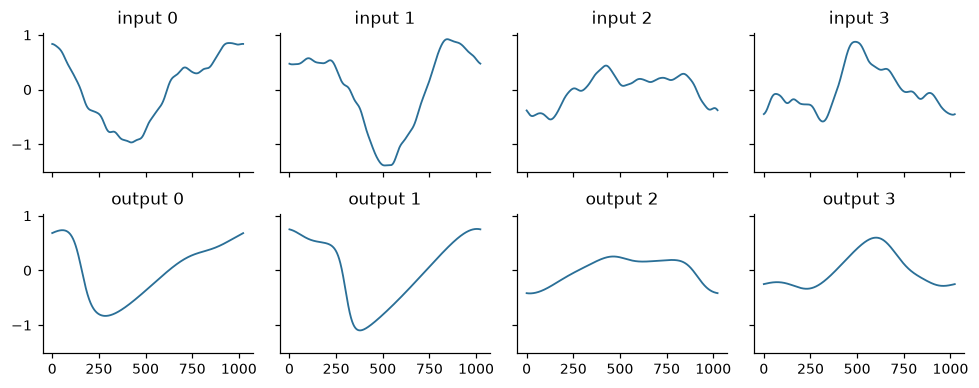

In [2]:
# Sample pairs. Signed fields use a diverging map centred on zero.
fig, ax = plt.subplots(2, 4, figsize=(9, 4.2 if two_d else 3.6), sharex=True, sharey=not two_d)
for j in range(4):
    for r, (v, t) in enumerate([(x, "input"), (y, "output")]):
        if two_d:
            l = v[j].abs().max(); ax[r, j].imshow(v[j], cmap="RdBu_r", vmin=-l, vmax=l); ax[r, j].axis("off")
        else:
            ax[r, j].plot(v[j], lw=1.2, color="#2a6f97")
        ax[r, j].set_title(f"{t} {j}")
plt.tight_layout()

||mean output|| / mean ||output|| = 0.018148714676499367


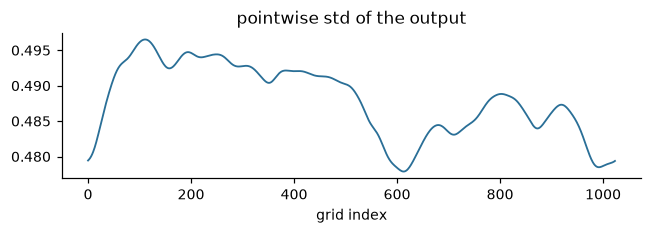

In [3]:
# How much of the output is shared structure? Mean norm vs sample norm, plus pointwise spread.
ys = y.std(0)
print("||mean output|| / mean ||output|| =", (y.mean(0).norm() / y.flatten(1).norm(dim=1).mean()).item())
if two_d:
    fig, ax = plt.subplots(1, 2, figsize=(6.4, 2.8))
    for a_, v, t in zip(ax, (y.mean(0), ys), ("mean output", "pointwise std")):
        im = a_.imshow(v, cmap="RdBu_r" if t.startswith("mean") else "Blues"); a_.set_title(t); a_.axis("off"); plt.colorbar(im, ax=a_, shrink=.8)
else:
    plt.figure(figsize=(6, 2.2)); plt.plot(ys, lw=1.2, color="#2a6f97"); plt.title("pointwise std of the output"); plt.xlabel("grid index")
plt.tight_layout()

best rL2 with 70 linear output modes ~ 0.00%
best rL2 with 120 linear output modes ~ 0.00%
best rL2 with 500 linear output modes ~ 0.00%


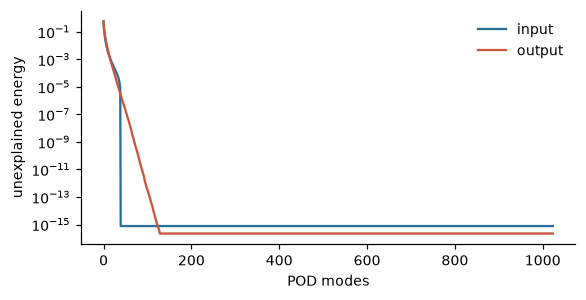

In [4]:
# Linear reducibility: POD energy. Slow decay means a low-rank basis (e.g. LMC with r latents) cannot be accurate.
def pod(t):
    t = t.flatten(1).double(); t = t - t.mean(0)
    s = torch.linalg.svdvals(t.cuda() if torch.cuda.is_available() else t).cpu()
    return (s ** 2).cumsum(0) / (s ** 2).sum()
ex, ey = pod(x), pod(y)
plt.figure(figsize=(5.4, 2.8))
plt.semilogy(1 - ex, label="input", color="#2a6f97", lw=1.5); plt.semilogy(1 - ey, label="output", color="#c8553d", lw=1.5)
plt.xlabel("POD modes"); plt.ylabel("unexplained energy"); plt.legend(frameon=False); plt.tight_layout()
for r in (70, 120, 500):
    if r < len(ey):
        print(f"best rL2 with {r} linear output modes ~ {100 * (1 - ey[r - 1].item()) ** .5:.2f}%")

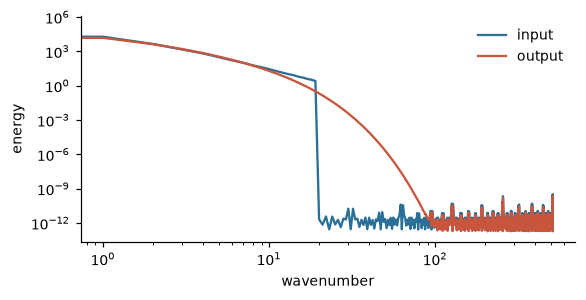

In [5]:
# Spectral content of inputs and outputs.
def spectrum(t):
    if two_d:
        F = torch.fft.fft2(t).abs().pow(2).mean(0); n = t.shape[-1]
        k = torch.fft.fftfreq(n, 1 / n); r = (k[None] ** 2 + k[:, None] ** 2).sqrt().round().long()
        return torch.zeros(r.max() + 1).scatter_add_(0, r.flatten(), F.flatten())[: n // 2]
    return torch.fft.rfft(t).abs().pow(2).mean(0)
plt.figure(figsize=(5.4, 2.8))
plt.loglog(spectrum(x)[1:], label="input", color="#2a6f97", lw=1.5); plt.loglog(spectrum(y)[1:], label="output", color="#c8553d", lw=1.5)
plt.xlabel("wavenumber"); plt.ylabel("energy"); plt.legend(frameon=False); plt.tight_layout()

In [6]:
# Train-test separation: nearest training input for the held-out block, the leakage check.
ntr = int(.85 * N); fx = x.flatten(1)
d = torch.cdist(fx[ntr:], fx[:ntr]).min(1).values / fx[ntr:].norm(dim=1)
print(f"relative distance to nearest train input: min {d.min():.3f}, median {d.median():.3f}")
pd.Series({"predict train mean, rL2 %": 100 * ((y[ntr:] - y[:ntr].mean(0)).flatten(1).norm(dim=1) / y[ntr:].flatten(1).norm(dim=1)).mean().item()})

relative distance to nearest train input: min 0.113, median 0.316


predict train mean, rL2 %    100.173402
dtype: float64